In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

np.random.seed(42)

In [2]:
n = 1000

area = np.random.normal(1800, 500, n).clip(500, 4000)

bedrooms = np.round(
    area / 500 + np.random.normal(0, 0.5, n)
).clip(1, 7)

bathrooms = np.round(
    bedrooms * 0.7 + np.random.normal(0, 0.4, n)
).clip(1, 5)

age = np.random.randint(0, 40, n)

distance = np.random.uniform(1, 30, n)

garage = np.random.choice([0, 1], n, p=[0.3, 0.7])

lot_size = area * np.random.uniform(1.2, 2.5, n)

school_rating = np.random.uniform(1, 10, n)

price = (
    5000000
    + area * 12000
    + bedrooms * 500000
    + bathrooms * 700000
    - age * 50000
    - distance * 100000
    + garage * 1000000
    + school_rating * 300000
    + np.random.normal(0, 4000000, n)
)

df = pd.DataFrame({
    "area": area,
    "bedrooms": bedrooms,
    "bathrooms": bathrooms,
    "age": age,
    "distance": distance,
    "garage": garage,
    "lot_size": lot_size,
    "school_rating": school_rating,
    "price": price
})

df.head()

,area,bedrooms,bathrooms,age,distance,garage,lot_size,school_rating,price
0,2048.357077,5.0,3.0,27,3.389773,0,3870.476159,1.351708,3.385326e+07
1,1730.867849,4.0,3.0,29,18.399068,1,3568.394290,6.746894,2.939482e+07
2,2123.844269,4.0,2.0,8,15.083759,1,4178.073183,1.455372,3.370143e+07
3,2561.514928,5.0,3.0,38,16.831782,1,4481.404538,9.336520,4.703251e+07
4,1682.923313,4.0,2.0,30,27.859951,1,2458.987131,9.654681,2.513040e+07


In [3]:
X = df.drop("price", axis=1)
y = df["price"]

In [4]:
print(df.shape)
print(df.info())
print(df.isnull().sum())
print(df.describe())

(1000, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   area           1000 non-null   float64
 1   bedrooms       1000 non-null   float64
 2   bathrooms      1000 non-null   float64
 3   age            1000 non-null   int64  
 4   distance       1000 non-null   float64
 5   garage         1000 non-null   int64  
 6   lot_size       1000 non-null   float64
 7   school_rating  1000 non-null   float64
 8   price          1000 non-null   float64
dtypes: float64(7), int64(2)
memory usage: 70.4 KB
None
area             0
bedrooms         0
bathrooms        0
age              0
distance         0
garage           0
lot_size         0
school_rating    0
price            0
dtype: int64
              area     bedrooms    bathrooms          age     distance  \
count  1000.000000  1000.000000  1000.000000  1000.000000  1000.000000   
mean   1810.0

In [5]:
correlation = df.corr(numeric_only=True)
print(correlation["price"].sort_values(ascending=False))

price            1.000000
area             0.849257
bedrooms         0.760165
bathrooms        0.699726
lot_size         0.670266
school_rating    0.146171
garage           0.108441
distance        -0.110651
age             -0.119465
Name: price, dtype: float64


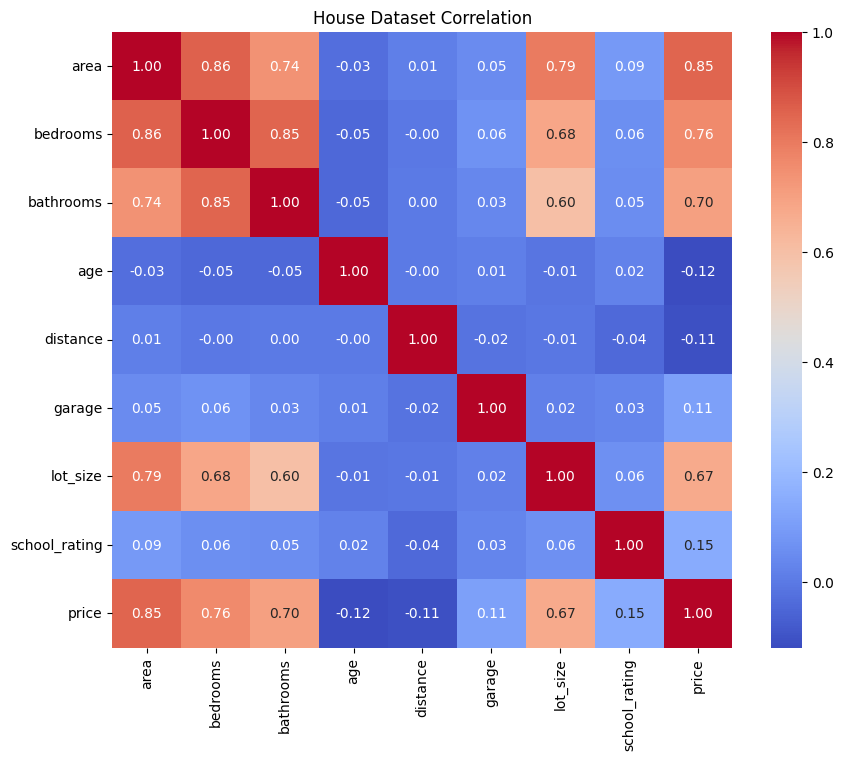

In [6]:
plt.figure(figsize=(10, 8))
sns.heatmap(correlation, annot=True,cmap="coolwarm",fmt=".2f")
plt.title("House Dataset Correlation")
plt.show()

In [7]:
from sklearn.feature_selection import mutual_info_regression

X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42
)

mi_scores=mutual_info_regression(X_train,y_train,random_state=42)

mi=pd.Series(mi_scores,index=X_train.columns).sort_values(ascending=False)
print(mi)

area             0.655231
bedrooms         0.412336
bathrooms        0.340314
lot_size         0.270822
age              0.028537
distance         0.015359
garage           0.000000
school_rating    0.000000
dtype: float64


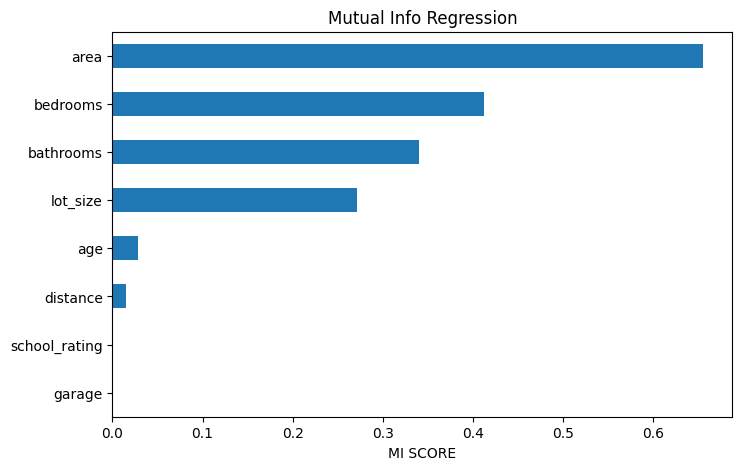

In [11]:
mi.sort_values().plot(
kind="barh",
figsize=(8,5)
)
plt.title("Mutual Info Regression")
plt.xlabel("MI SCORE")
plt.show()


In [12]:
#Variance Inflation Factor -VIF
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import (variance_inflation_factor)
X_vif=sm.add_constant(X_train)  # adds intercept column
vif_data=pd.DataFrame(
    {
        "Feature":X_vif.columns,
        "VIF":[variance_inflation_factor(
            X_vif.values,i
        ) for i in range(X_vif.shape[1])
        ]
    }
)
vif_data=vif_data[
    vif_data["Feature"] != "const"
]
print(vif_data.sort_values(
    "VIF",ascending=False
))

         Feature       VIF
2       bedrooms  6.218050
1           area  5.380469
3      bathrooms  3.753892
7       lot_size  2.649562
8  school_rating  1.017391
6         garage  1.011132
5       distance  1.006386
4            age  1.005787


In [15]:
#RFECV - recursive feature elimination with CV
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold
estimator=make_pipeline(
    StandardScaler(),
    LinearRegression()
)
rfecv=RFECV(
    estimator= estimator,
    step=1,
    cv=KFold(
        5,shuffle=True,random_state=42
    ),
    scoring="r2",
    min_features_to_select=3,
    importance_getter="named_steps.linearregression.coef_"
)
rfecv.fit(X_train,y_train)
selected_features=X_train.columns[
    rfecv.support_
]
print("SelectedFeatures:")
print(list(selected_features))
print("No. of features:",rfecv.n_features_)

SelectedFeatures:
['area', 'bedrooms', 'bathrooms', 'age', 'distance', 'garage', 'lot_size', 'school_rating']
No. of features: 8


In [17]:
#LASSO
from sklearn.linear_model import LassoCV
lasso=make_pipeline(
    StandardScaler(),
    LassoCV(cv=5,random_state=42)
)
lasso.fit(X_train,y_train)
coeff=pd.Series(
    lasso[-1].coef_,
    index=X_train.columns
)
print("All coeff:")
print(coeff)

print("\nSelected features:")
print(coeff[
    coeff!=0
])

All coeff:
area             5.871042e+06
bedrooms        -0.000000e+00
bathrooms        1.259631e+06
age             -7.572327e+05
distance        -9.220701e+05
garage           4.838167e+05
lot_size        -0.000000e+00
school_rating    6.066322e+05
dtype: float64

Selected features:
area             5.871042e+06
bathrooms        1.259631e+06
age             -7.572327e+05
distance        -9.220701e+05
garage           4.838167e+05
school_rating    6.066322e+05
dtype: float64


In [22]:
#permutation importance
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score

rf=RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf.fit(X_train,y_train)

res = permutation_importance(
    rf,#model
    X_test,
    y_test,
    n_repeats=10,
    scoring="r2",
    random_state=42
)
imp=pd.Series(
    res.importances_mean,
    index=X_test.columns
).sort_values(ascending=False)

print(imp)

area             1.225944
distance         0.022189
age              0.009524
bathrooms        0.007831
bedrooms         0.006840
garage           0.002715
lot_size         0.001924
school_rating   -0.000066
dtype: float64


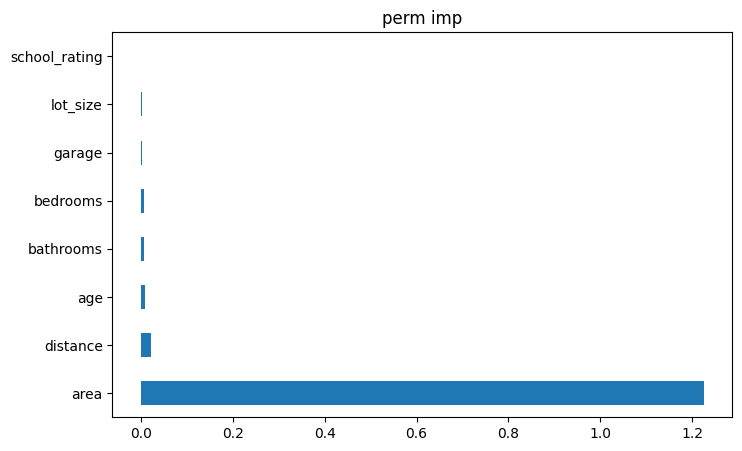

In [23]:
imp.plot(
    kind="barh",
    figsize=(8,5)
)
plt.title("perm imp")
plt.show()

In [24]:
median=y_train.median()

y_train_class=(
    y_train>median
).astype(int)

y_test_class=(
    y_test>median
).astype(int)

print(y_train_class.value_counts())

price
0    400
1    400
Name: count, dtype: int64


In [31]:
from sklearn.preprocessing import StandardScaler
import numpy as np

features=[
    "area",
    "age",
    "distance",
    "garage",
    "school_rating"
]

scaler=StandardScaler()

X_logit_train=scaler.fit_transform(
    X_train[features]
)

X_logit_test=scaler.transform(
    X_test[features]
)

X_logit_train=sm.add_constant(
    X_logit_train
)

model=sm.Logit(
    y_train_class,
    X_logit_train
).fit(disp=False)


In [32]:
X_logit_test=sm.add_constant(
    X_logit_test,
    has_constant="add"
)
y_pred_logit=model.predict(
    X_logit_test
)
y_pred_class=(
    y_pred_logit>=0.5
).astype(int)

results=pd.DataFrame({
    "ACtual Price Class" : y_test_class.values,
    "Predicted Price Class (Class 0)": 1-y_pred_logit,
    "Predicted Prob (Class 1)": y_pred_logit,
    "Pred Class" : y_pred_class
})
print(results.head(10).round(3))


   ACtual Price Class  Predicted Price Class (Class 0)  \
0                   1                            0.213   
1                   1                            0.136   
2                   0                            0.992   
3                   0                            0.696   
4                   0                            0.965   
5                   1                            0.068   
6                   0                            0.922   
7                   0                            0.873   
8                   0                            0.176   
9                   0                            0.933   

   Predicted Prob (Class 1)  Pred Class  
0                     0.787           1  
1                     0.864           1  
2                     0.008           0  
3                     0.304           0  
4                     0.035           0  
5                     0.932           1  
6                     0.078           0  
7                     0.1